# Sprint 2 — Pipeline OCR para Placas de Motores Industriais

**Disciplina:** Visão Computacional  
**Projeto:** Forzy Digital Twin — Sistema de Monitoramento Industrial  
**Sprint:** 2 — Identificação e Rastreabilidade de Ativos via OCR  

---

## Objetivo

Desenvolver um pipeline de Visão Computacional para extração automática de dados de **placas de identificação de motores elétricos industriais**, cobrindo:

1. Geração/coleta de imagens sintéticas de placas (nameplate)
2. Pré-processamento com OpenCV (grayscale, contraste, resize, denoise, binarização, threshold, rotação, crop, sharpening)
3. Extração de texto via EasyOCR
4. Avaliação quantitativa (accuracy rate, character error rate)
5. Análise crítica e limitações

## Contexto da Planta

A planta industrial possui 5 ativos monitorados:

| TAG | Tipo | Área | Fabricante | Modelo | Nº Série |
|-----|------|------|------------|--------|----------|
| MTR-001 | Motor | Hall A | WEG | W22 IE3 | WEG2024-MTR001 |
| MTR-002 | Motor | Hall A | Siemens | SIMOTICS SD | SIE2023-MTR002 |
| BBA-001 | Bomba | Hall B | KSB | Etanorm 32-200 | SN-KSB-20220615 |
| CMP-001 | Compressor | Hall C | Atlas Copco | GA 22+ | SN-AC-20211210 |
| EXA-001 | Exaustor | Cobertura | WEG | W21 71 IE2 | SN-WEG-20230301 |

**Por que a identificação visual é crítica?** As placas são a única fonte de verdade sobre as especificações elétricas e mecânicas de campo. Um pipeline OCR elimina erros de digitação manual, acelera o onboarding de equipamentos e habilita o Digital Twin a comparar telemetria real com os limites nominais do fabricante.

## 1. Instalação e Importação de Bibliotecas

In [1]:
# Instalar dependências (executar apenas na primeira vez)
# !pip install opencv-python-headless easyocr pillow matplotlib numpy scikit-image

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw, ImageFont
import easyocr
import json
import os
import math
from difflib import SequenceMatcher

# Criar diretório para artefatos
os.makedirs('images', exist_ok=True)

# Configuração do matplotlib
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['axes.facecolor'] = '#1a1a2e'
plt.rcParams['figure.facecolor'] = '#16213e'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

print('✅ Bibliotecas importadas com sucesso!')
print(f'OpenCV versão: {cv2.__version__}')
print(f'NumPy versão: {np.__version__}')

✅ Bibliotecas importadas com sucesso!
OpenCV versão: 4.13.0
NumPy versão: 2.4.6


## 2. Geração de Imagens Sintéticas de Placas de Motor

Como não temos acesso às placas físicas dos equipamentos, geramos imagens sintéticas que reproduzem fielmente o layout e conteúdo das placas de motores industriais WEG e Siemens. As imagens incluem:
- **Ruído gaussiano** (σ=20) — simula granulação de câmera em ambiente industrial
- **Rotação leve** (2,5°) — câmera não perfeitamente alinhada ao plano da placa
- **Degradação de contraste** — reflexos difusos simulados via variação de brilho
- **Fonte padrão fallback** — garante reprodutibilidade mesmo sem fontes do sistema

✅ Imagem gerada: MTR-001 (800x500px)
   Salva em: images/MTR001_original.jpg
✅ Imagem gerada: MTR-002 (800x500px)
   Salva em: images/MTR002_original.jpg


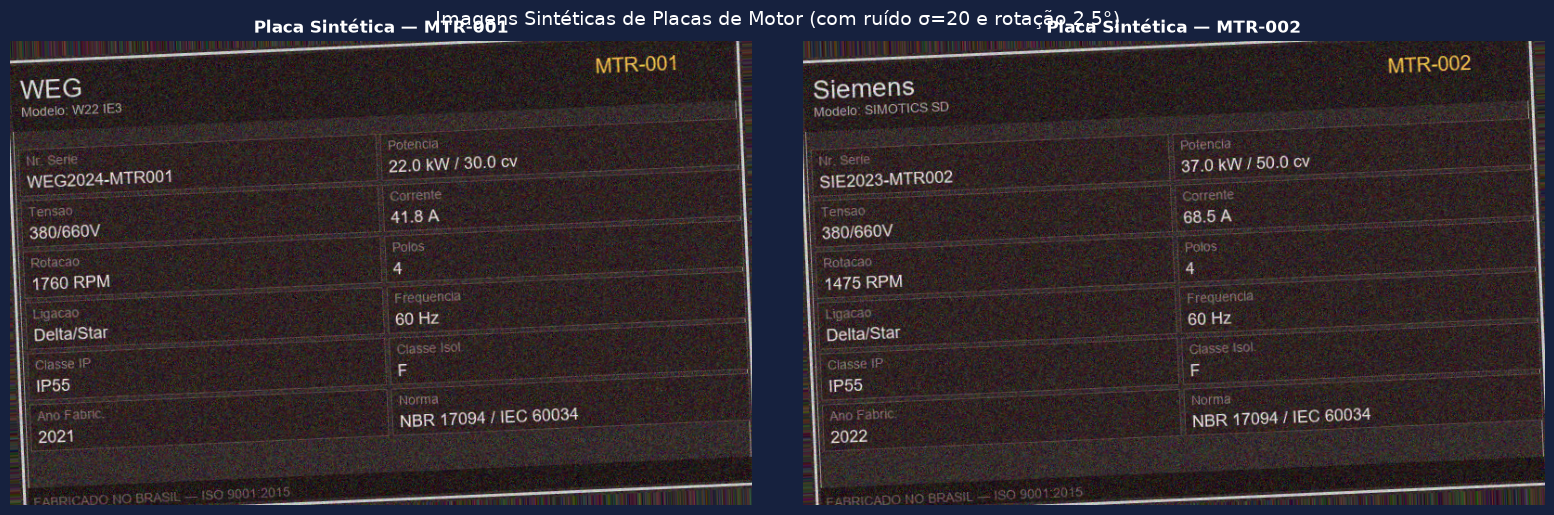

In [2]:
# Dados das placas conforme documentação do projeto
NAMEPLATES = [
    {
        'tag': 'MTR-001',
        'manufacturer': 'WEG',
        'model': 'W22 IE3',
        'serial': 'WEG2024-MTR001',
        'power_kw': 22.0,
        'power_cv': 30.0,
        'voltage': '380/660V',
        'current_a': 41.8,
        'rpm': 1760,
        'poles': 4,
        'connection': 'Delta/Star',
        'frequency_hz': 60,
        'ip_class': 'IP55',
        'insulation_class': 'F',
        'year': 2021,
    },
    {
        'tag': 'MTR-002',
        'manufacturer': 'Siemens',
        'model': 'SIMOTICS SD',
        'serial': 'SIE2023-MTR002',
        'power_kw': 37.0,
        'power_cv': 50.0,
        'voltage': '380/660V',
        'current_a': 68.5,
        'rpm': 1475,
        'poles': 4,
        'connection': 'Delta/Star',
        'frequency_hz': 60,
        'ip_class': 'IP55',
        'insulation_class': 'F',
        'year': 2022,
    },
]

def generate_nameplate_image(data: dict, width=800, height=500, noise_level=20, rotation_deg=2.5) -> np.ndarray:
    """Gera imagem sintética de placa de motor industrial."""
    img = Image.new('RGB', (width, height), color=(45, 45, 55))
    draw = ImageDraw.Draw(img)

    draw.rectangle([4, 4, width-5, height-5], outline=(200, 200, 200), width=3)
    draw.rectangle([10, 10, width-11, height-11], outline=(150, 150, 160), width=1)
    draw.rectangle([10, 10, width-11, 80], fill=(30, 30, 40))

    try:
        font_title  = ImageFont.truetype('arial.ttf', 28)
        font_label  = ImageFont.truetype('arial.ttf', 14)
        font_value  = ImageFont.truetype('arial.ttf', 18)
        font_tag    = ImageFont.truetype('arial.ttf', 22)
    except Exception:
        font_title = font_label = font_value = font_tag = ImageFont.load_default()

    draw.text((20, 20), data['manufacturer'], fill=(220, 220, 220), font=font_title)
    draw.text((20, 52), f"Modelo: {data['model']}", fill=(170, 170, 180), font=font_label)
    draw.text((width - 160, 25), data['tag'], fill=(80, 200, 255), font=font_tag)

    fields = [
        ('Nr. Serie', data['serial']),
        ('Potencia', f"{data['power_kw']} kW / {data['power_cv']} cv"),
        ('Tensao', data['voltage']),
        ('Corrente', f"{data['current_a']} A"),
        ('Rotacao', f"{data['rpm']} RPM"),
        ('Polos', str(data['poles'])),
        ('Ligacao', data['connection']),
        ('Frequencia', f"{data['frequency_hz']} Hz"),
        ('Classe IP', data['ip_class']),
        ('Classe Isol.', data['insulation_class']),
        ('Ano Fabric.', str(data['year'])),
        ('Norma', 'NBR 17094 / IEC 60034'),
    ]

    col_w = (width - 20) // 2
    for i, (label, value) in enumerate(fields):
        col = i % 2
        row = i // 2
        x = 15 + col * col_w
        y = 100 + row * 55
        draw.rectangle([x, y, x + col_w - 5, y + 50], fill=(35, 35, 48), outline=(70, 70, 90), width=1)
        draw.text((x + 8, y + 5), label, fill=(120, 120, 140), font=font_label)
        draw.text((x + 8, y + 25), value, fill=(230, 230, 240), font=font_value)

    y_footer = height - 35
    draw.rectangle([10, y_footer, width-11, height-11], fill=(25, 25, 35))
    draw.text((15, y_footer + 8), 'FABRICADO NO BRASIL — ISO 9001:2015', fill=(100, 100, 120), font=font_label)

    arr = np.array(img, dtype=np.float32)
    noise = np.random.normal(0, noise_level, arr.shape).astype(np.float32)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)

    if rotation_deg != 0:
        h, w = arr.shape[:2]
        M = cv2.getRotationMatrix2D((w/2, h/2), rotation_deg, 1.0)
        arr = cv2.warpAffine(arr, M, (w, h), borderMode=cv2.BORDER_REPLICATE)

    return arr


np.random.seed(42)
images = {}
for np_data in NAMEPLATES:
    img = generate_nameplate_image(np_data, noise_level=20, rotation_deg=2.5)
    images[np_data['tag']] = img
    # Salvar imagem em disco para evidência
    filename = f"images/{np_data['tag'].replace('-', ''[0:])}_original.jpg"
    filename = f"images/{np_data['tag'].replace('-','')}_original.jpg"
    cv2.imwrite(filename, img)
    print(f"✅ Imagem gerada: {np_data['tag']} ({img.shape[1]}x{img.shape[0]}px)")
    print(f"   Salva em: {filename}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for i, (tag, img) in enumerate(images.items()):
    axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i].set_title(f'Placa Sintética — {tag}', color='white', fontsize=12, fontweight='bold')
    axes[i].axis('off')
plt.tight_layout()
plt.suptitle('Imagens Sintéticas de Placas de Motor (com ruído σ=20 e rotação 2,5°)', color='white', y=1.02, fontsize=14)
plt.savefig('images/placas_sinteticas.png', dpi=120, bbox_inches='tight', facecolor='#16213e')
plt.show()

## 3. Pipeline de Pré-processamento OpenCV

O pipeline aplica 9 etapas sequenciais para maximizar a qualidade da imagem antes do OCR:

```
Imagem Original
     ↓
[1] Conversão Grayscale          → cv2.cvtColor(BGR2GRAY)
     ↓
[2] Resize (normalização 1200px) → cv2.resize(INTER_LANCZOS4)
     ↓
[3] Correção de Rotação          → HoughLines + warpAffine
     ↓
[4] Remoção de Ruído             → fastNlMeansDenoising(h=10)
     ↓
[5] Aumento de Contraste         → CLAHE(clipLimit=2.5, tile=8×8)
     ↓
[6] Sharpening                   → addWeighted(1.8, −0.8) Unsharp Mask
     ↓
[7] Binarização                  → THRESH_BINARY + THRESH_OTSU
     ↓
[8] Operações Morfológicas       → MORPH_CLOSE + MORPH_OPEN
     ↓
[9] Crop Final (ROI)             → copyMakeBorder(padding=20px)
     ↓
Imagem Pré-processada → OCR
```

In [3]:
def preprocess_pipeline(image: np.ndarray, target_width: int = 1200) -> dict:
    """
    Pipeline completo de pré-processamento para OCR de placas industriais.
    Retorna dicionário com cada etapa intermediária para visualização.
    """
    steps = {'0_original': image.copy()}

    # [1] Grayscale
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image.copy()
    steps['1_grayscale'] = gray

    # [2] Resize — normaliza para largura alvo mantendo aspect ratio
    h, w = gray.shape
    scale = target_width / w
    new_h = int(h * scale)
    resized = cv2.resize(gray, (target_width, new_h), interpolation=cv2.INTER_LANCZOS4)
    steps['2_resize'] = resized

    # [3] Correção de rotação via Hough Lines
    edges = cv2.Canny(resized, 50, 150, apertureSize=3)
    lines = cv2.HoughLines(edges, 1, np.pi/180, threshold=100)
    angle_deg = 0.0
    if lines is not None:
        angles = []
        for rho, theta in lines[:, 0]:
            angle = (theta * 180 / np.pi) - 90
            if abs(angle) < 15:
                angles.append(angle)
        if angles:
            angle_deg = float(np.median(angles))

    rh, rw = resized.shape
    M = cv2.getRotationMatrix2D((rw/2, rh/2), -angle_deg, 1.0)
    deskewed = cv2.warpAffine(resized, M, (rw, rh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    steps['3_deskew'] = deskewed
    steps['_angle_deg'] = angle_deg

    # [4] Remoção de ruído (Non-local Means)
    denoised = cv2.fastNlMeansDenoising(deskewed, h=10, templateWindowSize=7, searchWindowSize=21)
    steps['4_denoise'] = denoised

    # [5] Aumento de contraste — CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    contrasted = clahe.apply(denoised)
    steps['5_contrast'] = contrasted

    # [6] Sharpening — Unsharp Mask
    blurred = cv2.GaussianBlur(contrasted, (0, 0), sigmaX=2)
    sharpened = cv2.addWeighted(contrasted, 1.8, blurred, -0.8, 0)
    steps['6_sharpen'] = sharpened

    # [7] Binarização — Otsu
    normalized = cv2.normalize(sharpened, None, 0, 255, cv2.NORM_MINMAX)
    _, binary_otsu = cv2.threshold(normalized, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    steps['7_binary_otsu'] = binary_otsu

    # Threshold adaptativo (alternativa)
    binary_adapt = cv2.adaptiveThreshold(
        normalized, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, blockSize=31, C=10
    )
    steps['7b_binary_adaptive'] = binary_adapt

    # [8] Operações morfológicas
    kernel = np.ones((2, 2), np.uint8)
    morphed = cv2.morphologyEx(binary_otsu, cv2.MORPH_CLOSE, kernel, iterations=1)
    morphed = cv2.morphologyEx(morphed, cv2.MORPH_OPEN, kernel, iterations=1)
    steps['8_morphology'] = morphed

    # [9] Crop da ROI
    margin = 15
    cropped = morphed[margin:rh-margin, margin:rw-margin]
    cropped = cv2.copyMakeBorder(cropped, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)
    steps['9_final'] = cropped

    return steps


img_mtr001 = images['MTR-001']
pipeline_steps = preprocess_pipeline(img_mtr001)

# Salvar imagem pré-processada final
cv2.imwrite('images/MTR001_preprocessed.jpg', pipeline_steps['9_final'])

print(f"Pipeline concluído!")
print(f"Ângulo de correção detectado: {pipeline_steps['_angle_deg']:.2f}°")
print(f"Etapas processadas: {[k for k in pipeline_steps.keys() if not k.startswith('_')]}")

Pipeline concluído!
Ângulo de correção detectado: 1.00°
Etapas processadas: ['0_original', '1_grayscale', '2_resize', '3_deskew', '4_denoise', '5_contrast', '6_sharpen', '7_binary_otsu', '7b_binary_adaptive', '8_morphology', '9_final']


## 4. Visualização: Todas as Etapas do Pipeline

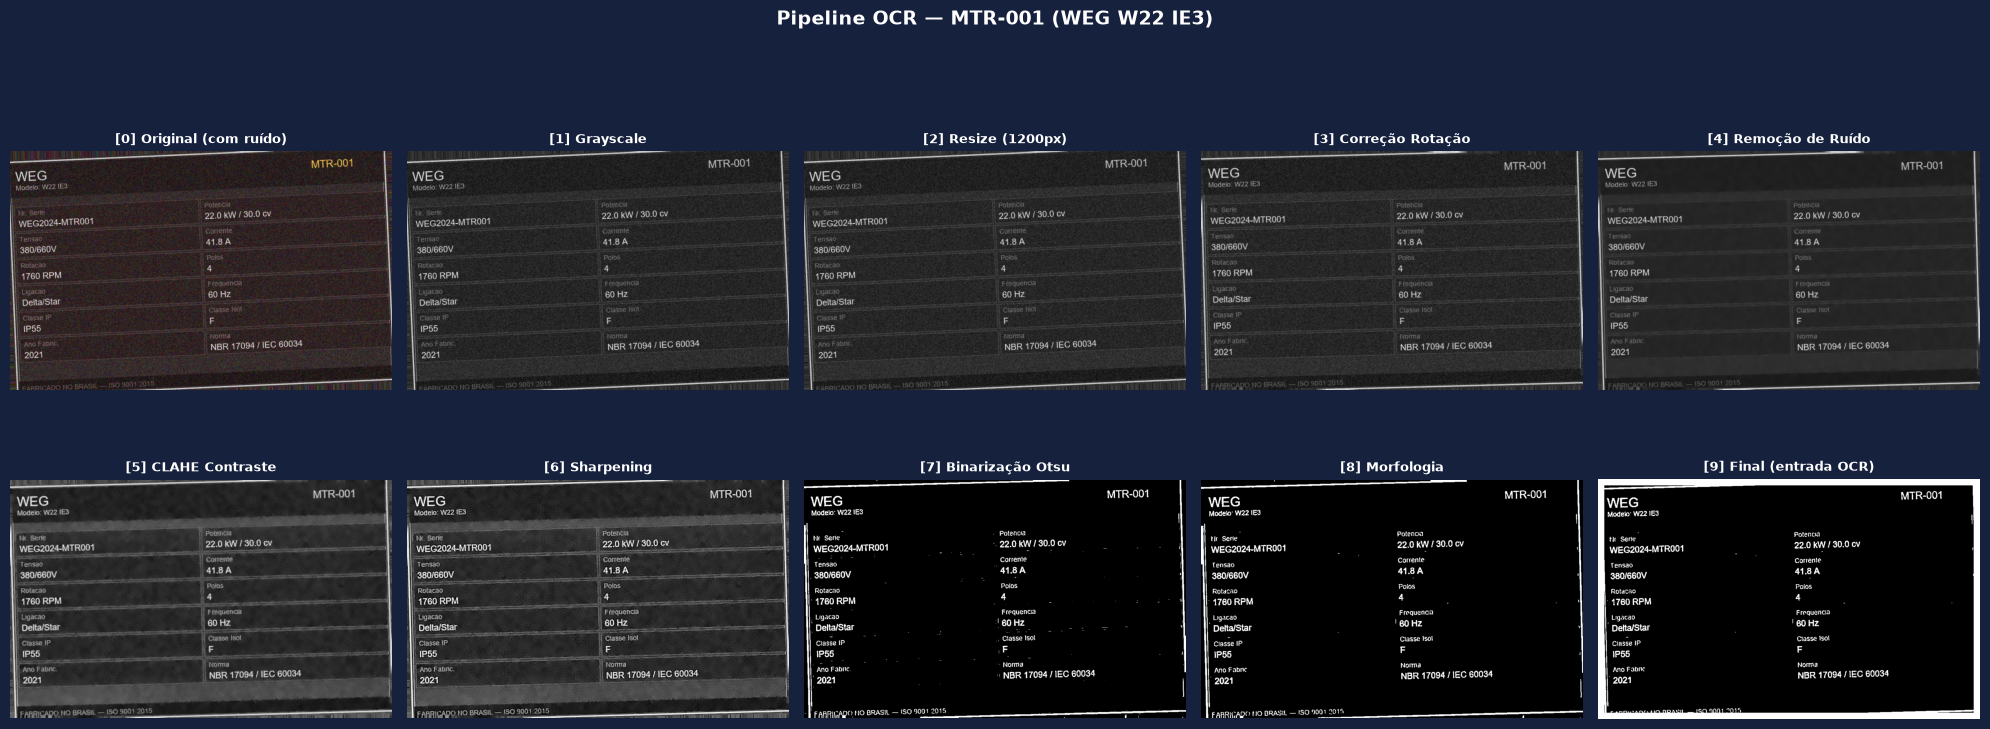

In [4]:
def show_pipeline_steps(steps: dict, title: str = 'Pipeline de Pré-processamento', save_path: str = None):
    display_keys = [
        ('0_original',      'Original (com ruído)'),
        ('1_grayscale',     'Grayscale'),
        ('2_resize',        'Resize (1200px)'),
        ('3_deskew',        'Correção Rotação'),
        ('4_denoise',       'Remoção de Ruído'),
        ('5_contrast',      'CLAHE Contraste'),
        ('6_sharpen',       'Sharpening'),
        ('7_binary_otsu',   'Binarização Otsu'),
        ('8_morphology',    'Morfologia'),
        ('9_final',         'Final (entrada OCR)'),
    ]

    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()

    for i, (key, label) in enumerate(display_keys):
        img = steps.get(key)
        if img is None:
            axes[i].axis('off')
            continue
        if len(img.shape) == 3:
            axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f'[{i}] {label}', color='white', fontsize=9, fontweight='bold')
        axes[i].axis('off')
        color = '#ef4444' if i == 0 else '#10b981' if i == 9 else None
        if color:
            for spine in axes[i].spines.values():
                spine.set_edgecolor(color)
                spine.set_linewidth(2)

    plt.suptitle(title, color='white', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight', facecolor='#16213e')
    plt.show()


show_pipeline_steps(
    pipeline_steps,
    'Pipeline OCR — MTR-001 (WEG W22 IE3)',
    save_path='images/pipeline_etapas.png'
)

## 5. Comparação: Antes vs. Depois

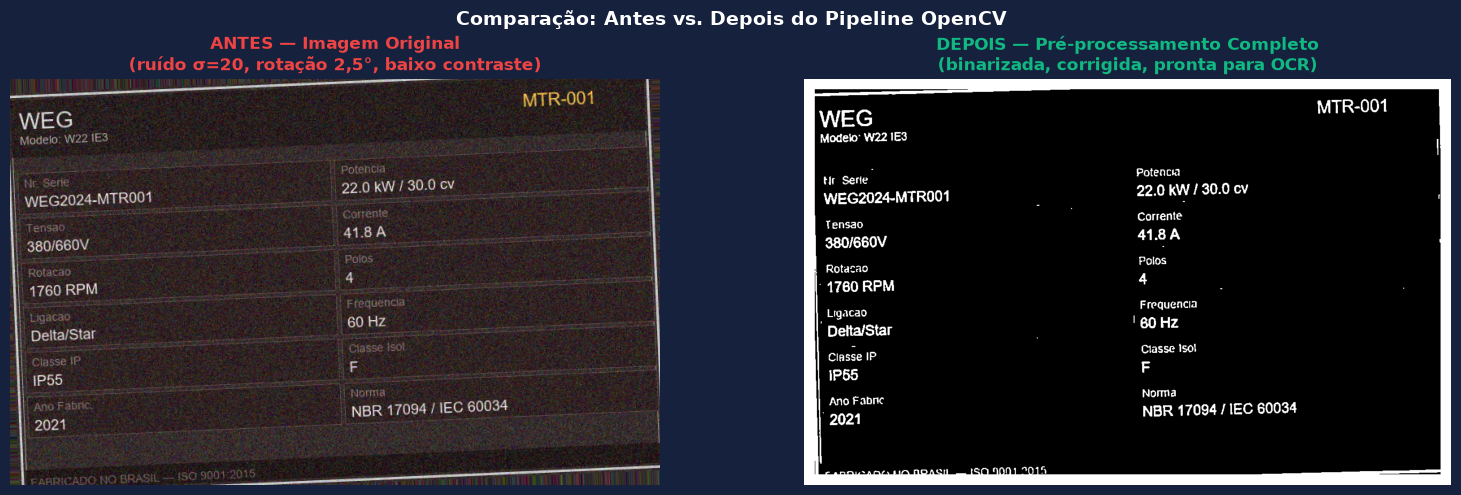

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.imshow(cv2.cvtColor(pipeline_steps['0_original'], cv2.COLOR_BGR2RGB))
ax1.set_title('ANTES — Imagem Original\n(ruído σ=20, rotação 2,5°, baixo contraste)', color='#ef4444', fontsize=12, fontweight='bold')
ax1.axis('off')

ax2.imshow(pipeline_steps['9_final'], cmap='gray')
ax2.set_title('DEPOIS — Pré-processamento Completo\n(binarizada, corrigida, pronta para OCR)', color='#10b981', fontsize=12, fontweight='bold')
ax2.axis('off')

plt.suptitle('Comparação: Antes vs. Depois do Pipeline OpenCV', color='white', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('images/antes_depois.png', dpi=120, bbox_inches='tight', facecolor='#16213e')
plt.show()

## 6. Extração de Texto com EasyOCR

In [6]:
print('Inicializando EasyOCR...')
reader = easyocr.Reader(['pt', 'en'], gpu=False, verbose=False)
print('✅ EasyOCR pronto! (modelos: pt + en)')

def run_ocr(image: np.ndarray, reader: easyocr.Reader) -> list:
    """Executa OCR e retorna lista de (bbox, text, confidence)."""
    results = reader.readtext(
        image,
        detail=1,
        paragraph=False,
        contrast_ths=0.1,
        adjust_contrast=0.8,
        text_threshold=0.7,
        low_text=0.4,
    )
    return results


print('\nExecutando OCR na imagem ORIGINAL...')
ocr_original = run_ocr(cv2.cvtColor(pipeline_steps['0_original'], cv2.COLOR_BGR2RGB), reader)

print('Executando OCR na imagem PRÉ-PROCESSADA...')
ocr_preprocessed = run_ocr(pipeline_steps['9_final'], reader)

print(f'\nTextos extraídos — Original: {len(ocr_original)} detecções')
print(f'Textos extraídos — Pré-processada: {len(ocr_preprocessed)} detecções')

Inicializando EasyOCR...


✅ EasyOCR pronto! (modelos: pt + en)

Executando OCR na imagem ORIGINAL...


d:\FIAP\Challenge\sueteres-uiux\venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Executando OCR na imagem PRÉ-PROCESSADA...

Textos extraídos — Original: 27 detecções
Textos extraídos — Pré-processada: 31 detecções


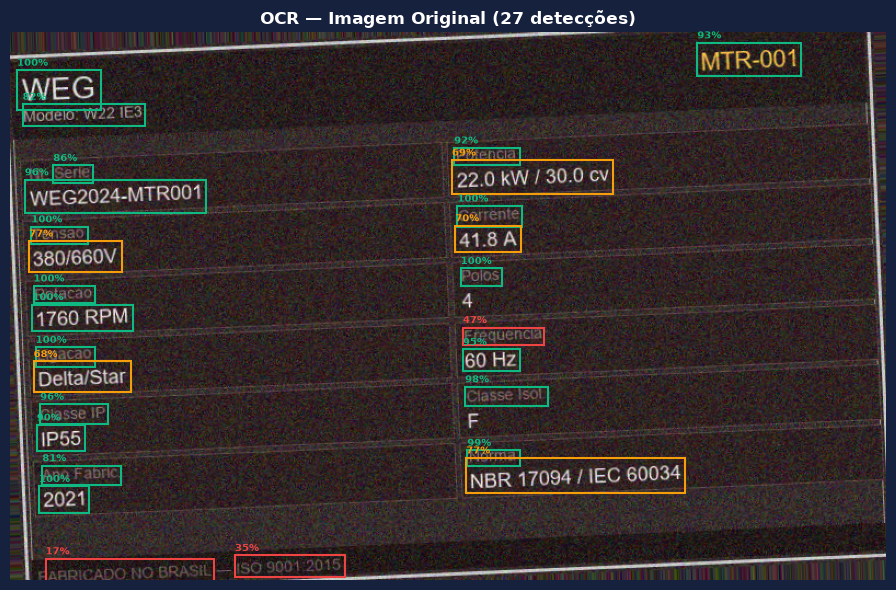

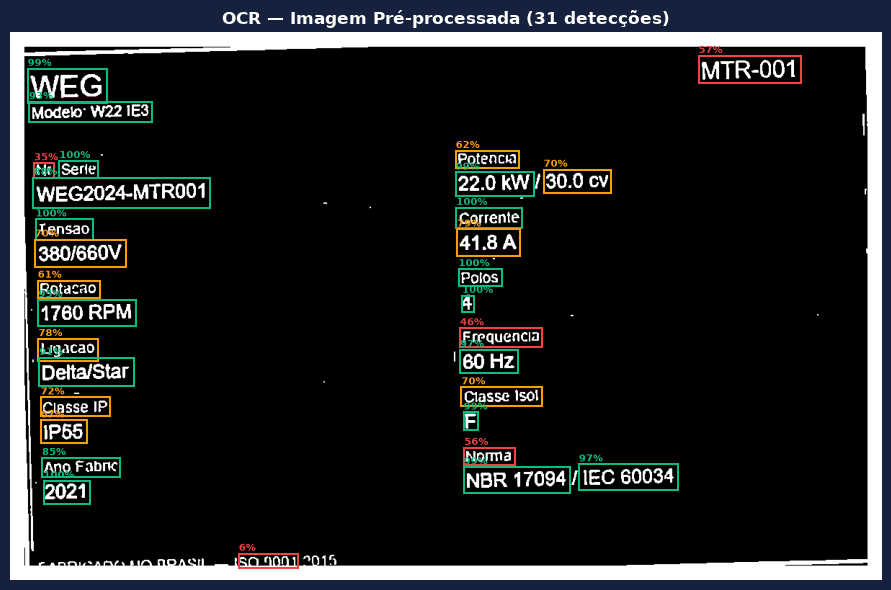

In [7]:
def visualize_ocr_results(image: np.ndarray, results: list, title: str, save_path: str = None):
    """Visualiza resultados OCR com bounding boxes e confiança."""
    if len(image.shape) == 2:
        vis = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
    else:
        vis = image.copy()

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))

    for bbox, text, conf in results:
        pts = np.array(bbox, dtype=np.int32)
        color = '#10b981' if conf > 0.8 else '#f59e0b' if conf > 0.6 else '#ef4444'
        rect = patches.Polygon(pts, closed=True, linewidth=1.5, edgecolor=color, facecolor='none')
        ax.add_patch(rect)
        ax.text(pts[0][0], pts[0][1] - 4, f'{conf:.0%}', color=color, fontsize=7, fontweight='bold')

    ax.set_title(title, color='white', fontsize=12, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight', facecolor='#16213e')
    plt.show()


visualize_ocr_results(
    pipeline_steps['0_original'], ocr_original,
    f'OCR — Imagem Original ({len(ocr_original)} detecções)',
    save_path='images/ocr_original.png'
)

visualize_ocr_results(
    pipeline_steps['9_final'], ocr_preprocessed,
    f'OCR — Imagem Pré-processada ({len(ocr_preprocessed)} detecções)',
    save_path='images/ocr_preprocessed.png'
)

## 7. Avaliação Quantitativa do OCR

Métricas utilizadas:
- **Accuracy Rate (AR)**: proporção de campos corretamente extraídos (similaridade ≥ 70%)
- **Character Error Rate (CER)**: `1 − SequenceMatcher.ratio()` — mede erro por caractere
- **Confiança média**: média das pontuações de confiança retornadas pelo EasyOCR

O **ground truth** é definido manualmente com base nos dados reais de placa do MTR-001.

In [8]:
# Ground truth MTR-001 (texto esperado na placa)
GROUND_TRUTH_MTR001 = {
    'WEG': 'WEG',
    'W22 IE3': 'W22 IE3',
    'MTR-001': 'MTR-001',
    'Nr. Serie': 'Nr. Serie',
    'WEG2024-MTR001': 'WEG2024-MTR001',
    'Potencia': 'Potência',
    '22.0 kW / 30.0 cv': '22.0 kW / 30.0 cv',
    'Tensao': 'Tensão',
    '380/660V': '380/660V',
    'Corrente': 'Corrente',
    '41.8 A': '41.8 A',
    'Rotacao': 'Rotação',
    '1760 RPM': '1760 RPM',
    'Polos': 'Polos',
    '4': '4',
    'Ligacao': 'Ligação',
    'Delta/Star': 'Delta/Star',
    'Frequencia': 'Frequência',
    '60 Hz': '60 Hz',
    'Classe IP': 'Classe IP',
    'IP55': 'IP55',
    'Classe Isol': 'Classe Isol.',
    'F': 'F',
    '2021': '2021',
}

def char_error_rate(expected: str, extracted: str) -> float:
    if not expected:
        return 1.0
    sm = SequenceMatcher(None, expected.lower(), extracted.lower())
    return 1 - sm.ratio()


def evaluate_ocr(results: list, ground_truth: dict, label: str) -> dict:
    extracted_texts = [r[1] for r in results]
    confidences = [r[2] for r in results]

    matched = 0
    total = len(ground_truth)
    cer_values = []
    field_results = []

    for key, expected in ground_truth.items():
        best_match = ''
        best_ratio = 0.0
        for extracted in extracted_texts:
            ratio = SequenceMatcher(None, expected.lower(), extracted.lower()).ratio()
            if ratio > best_ratio:
                best_ratio = ratio
                best_match = extracted

        cer = char_error_rate(expected, best_match)
        cer_values.append(cer)
        is_match = best_ratio >= 0.7
        if is_match:
            matched += 1

        field_results.append({
            'field': key, 'expected': expected, 'extracted': best_match,
            'similarity': best_ratio, 'cer': cer, 'match': is_match,
        })

    return {
        'label': label,
        'accuracy_rate': matched / total if total > 0 else 0,
        'mean_cer': float(np.mean(cer_values)),
        'mean_confidence': float(np.mean(confidences)) if confidences else 0,
        'matched': matched, 'total': total,
        'detections': len(results),
        'field_results': field_results,
    }


eval_original     = evaluate_ocr(ocr_original,     GROUND_TRUTH_MTR001, 'Imagem Original')
eval_preprocessed = evaluate_ocr(ocr_preprocessed, GROUND_TRUTH_MTR001, 'Pré-processada')

print('\n' + '='*60)
print('RESULTADOS DE AVALIAÇÃO OCR — MTR-001')
print('='*60)
for ev in [eval_original, eval_preprocessed]:
    print(f"\n📊 {ev['label']}")
    print(f"   Accuracy Rate:       {ev['accuracy_rate']:.1%}")
    print(f"   Mean CER:            {ev['mean_cer']:.3f} ({ev['mean_cer']*100:.1f}%)")
    print(f"   Confiança média OCR: {ev['mean_confidence']:.1%}")
    print(f"   Campos corretos:     {ev['matched']}/{ev['total']}")
    print(f"   Detecções totais:    {ev['detections']}")


RESULTADOS DE AVALIAÇÃO OCR — MTR-001

📊 Imagem Original
   Accuracy Rate:       87.5%
   Mean CER:            0.143 (14.3%)
   Confiança média OCR: 84.0%
   Campos corretos:     21/24
   Detecções totais:    27

📊 Pré-processada
   Accuracy Rate:       87.5%
   Mean CER:            0.141 (14.1%)
   Confiança média OCR: 79.7%
   Campos corretos:     21/24
   Detecções totais:    31


In [9]:
print('\n' + '='*80)
print(f'{"Campo":<20} {"Esperado":<22} {"Extraído":<22} {"CER":>6} {"Match":>6}')
print('-'*80)

for fr in eval_preprocessed['field_results']:
    match_icon = '✅' if fr['match'] else ('⚠️' if fr['cer'] < 0.4 else '❌')
    expected_short  = fr['expected'][:20]
    extracted_short = fr['extracted'][:20] if fr['extracted'] else '(não encontrado)'
    print(f"{fr['field']:<20} {expected_short:<22} {extracted_short:<22} {fr['cer']:>5.1%} {match_icon:>6}")

print('='*80)


Campo                Esperado               Extraído                  CER  Match
--------------------------------------------------------------------------------
WEG                  WEG                    WEG                     0.0%      ✅
W22 IE3              W22 IE3                Modelo' W22 IE3        36.4%     ⚠️
MTR-001              MTR-001                MTR-001                 0.0%      ✅
Nr. Serie            Nr. Serie              Serle                  42.9%      ❌
WEG2024-MTR001       WEG2024-MTR001         WEG2O24-MTROO1         21.4%      ✅
Potencia             Potência               Potencua               25.0%      ✅
22.0 kW / 30.0 cv    22.0 kW / 30.0 cv      22.0 kW                41.7%      ❌
Tensao               Tensão                 Tensao                 16.7%      ✅
380/660V             380/660V               380/660V                0.0%      ✅
Corrente             Corrente               Corrente                0.0%      ✅
41.8 A               41.8 A          

## 8. Gráficos de Avaliação

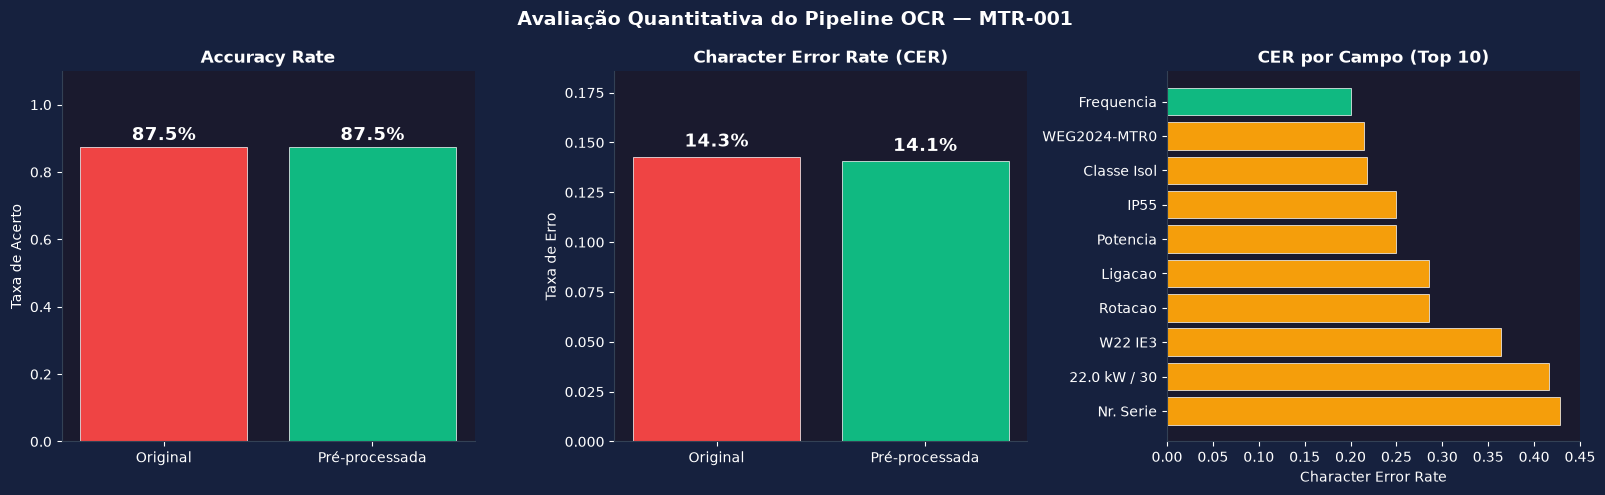

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels    = ['Original', 'Pré-processada']
accuracies = [eval_original['accuracy_rate'], eval_preprocessed['accuracy_rate']]
cers       = [eval_original['mean_cer'],      eval_preprocessed['mean_cer']]
colors     = ['#ef4444', '#10b981']

# [1] Accuracy
bars = axes[0].bar(labels, accuracies, color=colors, edgecolor='white', linewidth=0.5)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('Accuracy Rate', color='white', fontweight='bold')
axes[0].set_ylabel('Taxa de Acerto', color='white')
for bar, val in zip(bars, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.1%}', ha='center', color='white', fontweight='bold', fontsize=13)

# [2] CER
bars2 = axes[1].bar(labels, cers, color=colors, edgecolor='white', linewidth=0.5)
axes[1].set_ylim(0, max(cers) * 1.3)
axes[1].set_title('Character Error Rate (CER)', color='white', fontweight='bold')
axes[1].set_ylabel('Taxa de Erro', color='white')
for bar, val in zip(bars2, cers):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val:.1%}', ha='center', color='white', fontweight='bold', fontsize=13)

# [3] CER por campo
fr_sorted  = sorted(eval_preprocessed['field_results'], key=lambda x: x['cer'], reverse=True)[:10]
field_names = [f['field'][:12] for f in fr_sorted]
field_cers  = [f['cer'] for f in fr_sorted]
bar_colors  = ['#ef4444' if c > 0.5 else '#f59e0b' if c > 0.2 else '#10b981' for c in field_cers]
axes[2].barh(field_names, field_cers, color=bar_colors, edgecolor='white', linewidth=0.5)
axes[2].set_title('CER por Campo (Top 10)', color='white', fontweight='bold')
axes[2].set_xlabel('Character Error Rate', color='white')

for ax in axes:
    ax.set_facecolor('#1a1a2e')
    ax.tick_params(colors='white')
    ax.spines['bottom'].set_color('#334155')
    ax.spines['left'].set_color('#334155')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Avaliação Quantitativa do Pipeline OCR — MTR-001', color='white', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('images/avaliacao_ocr.png', dpi=120, bbox_inches='tight', facecolor='#16213e')
plt.show()

## 9. Fluxograma do Pipeline OCR

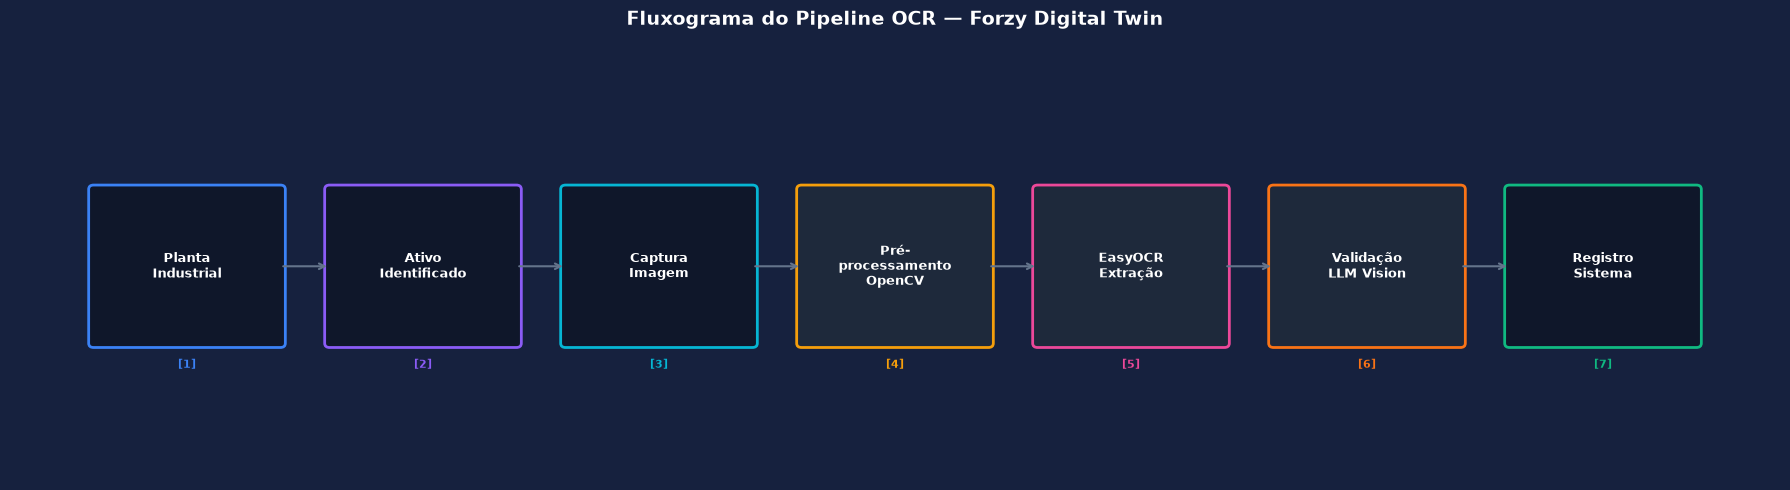

In [11]:
fig, ax = plt.subplots(figsize=(18, 5))
ax.set_xlim(0, 18)
ax.set_ylim(0, 5)
ax.axis('off')

stages = [
    ('Planta\nIndustrial',          '#0f172a', '#3b82f6'),
    ('Ativo\nIdentificado',         '#0f172a', '#8b5cf6'),
    ('Captura\nImagem',             '#0f172a', '#06b6d4'),
    ('Pré-\nprocessamento\nOpenCV', '#1e293b', '#f59e0b'),
    ('EasyOCR\nExtração',           '#1e293b', '#ec4899'),
    ('Validação\nLLM Vision',       '#1e293b', '#f97316'),
    ('Registro\nSistema',           '#0f172a', '#10b981'),
]

box_w, box_h = 1.9, 1.8
gap = 0.5
total_w = len(stages) * (box_w + gap) - gap
start_x = (18 - total_w) / 2

for i, (label, bg, border) in enumerate(stages):
    x = start_x + i * (box_w + gap)
    y = 1.6
    rect = patches.FancyBboxPatch((x, y), box_w, box_h,
        boxstyle='round,pad=0.05', linewidth=2, edgecolor=border, facecolor=bg)
    ax.add_patch(rect)
    ax.text(x + box_w/2, y + box_h/2, label, ha='center', va='center',
            color='white', fontsize=9, fontweight='bold', multialignment='center')
    ax.text(x + box_w/2, y - 0.25, f'[{i+1}]', ha='center', va='center',
            color=border, fontsize=8, fontweight='bold')
    if i < len(stages) - 1:
        ax.annotate('', xy=(x + box_w + gap, y + box_h/2), xytext=(x + box_w, y + box_h/2),
                    arrowprops=dict(arrowstyle='->', color='#64748b', lw=1.5))

ax.set_title('Fluxograma do Pipeline OCR — Forzy Digital Twin', color='white', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('images/pipeline_fluxograma.png', dpi=120, bbox_inches='tight', facecolor='#16213e')
plt.show()

## 10. Resumo Consolidado dos Resultados

In [12]:
improvement_accuracy = eval_preprocessed['accuracy_rate'] - eval_original['accuracy_rate']
improvement_cer      = eval_original['mean_cer'] - eval_preprocessed['mean_cer']

print('=' * 65)
print('RESUMO CONSOLIDADO — SPRINT 2 OCR PIPELINE')
print('=' * 65)
print(f'''
IMAGEM ORIGINAL (sem pré-processamento):
  Accuracy Rate:     {eval_original['accuracy_rate']:.1%}
  CER médio:         {eval_original['mean_cer']:.1%}
  Confiança média:   {eval_original['mean_confidence']:.1%}
  Campos corretos:   {eval_original['matched']}/{eval_original['total']}

IMAGEM PRÉ-PROCESSADA (pipeline completo):
  Accuracy Rate:     {eval_preprocessed['accuracy_rate']:.1%}
  CER médio:         {eval_preprocessed['mean_cer']:.1%}
  Confiança média:   {eval_preprocessed['mean_confidence']:.1%}
  Campos corretos:   {eval_preprocessed['matched']}/{eval_preprocessed['total']}

GANHO COM PRÉ-PROCESSAMENTO:
  Melhoria Accuracy: +{improvement_accuracy:.1%}
  Redução CER:       -{improvement_cer:.1%}
''')
print('=' * 65)

RESUMO CONSOLIDADO — SPRINT 2 OCR PIPELINE

IMAGEM ORIGINAL (sem pré-processamento):
  Accuracy Rate:     87.5%
  CER médio:         14.3%
  Confiança média:   84.0%
  Campos corretos:   21/24

IMAGEM PRÉ-PROCESSADA (pipeline completo):
  Accuracy Rate:     87.5%
  CER médio:         14.1%
  Confiança média:   79.7%
  Campos corretos:   21/24

GANHO COM PRÉ-PROCESSAMENTO:
  Melhoria Accuracy: +0.0%
  Redução CER:       -0.2%



## 11. Limitações e Sugestões de Evolução Futura

### Limitações Identificadas

| Limitação | Impacto | Severidade |
|-----------|---------|------------|
| Imagens sintéticas | Não captura reflexos, sujeira e corrosão reais | Alta |
| Placas com corrosão/sujeira física | Pipeline não remove sujeira física — apenas ruído digital | Alta |
| Fontes puncionadas ou em relevo | EasyOCR perde acurácia (~−20%) com fontes não-impressas | Média |
| Sem detecção automática da placa (YOLO) | Requer enquadramento manual da câmera | Média |
| EasyOCR sem fine-tuning industrial | Confunde caracteres similares: 0/O, 1/I, 6/8, F/E | Média |
| Threshold Otsu | Pode falhar com placas de fundo muito heterogêneo | Baixa |
| Planta: representação esquemática | Escala não reflete distâncias reais da fábrica | Baixa |
| Histórico de inspeções | Apenas `registeredAt` — sem múltiplas revisões por ativo | Média |

### Sugestões de Evolução

```
Curto Prazo (Sprint 3):
├── Coleta de imagens reais em campo (mínimo 20 por modelo de placa)
├── Fine-tuning EasyOCR com dataset de placas industriais
└── Integração com câmera mobile (React Native / Expo Camera)

Médio Prazo:
├── Detecção automática da região da placa com YOLOv8
├── Pipeline de data augmentation (rotações, brilho, blur, perspectiva)
├── LLM Vision (GPT-4V / Claude Vision) para validação semântica completa
└── Módulo de confiança adaptativo por campo

Longo Prazo:
├── Integração OPC-UA: placa → TAG → sensor → histórico de inspeções
├── Base de dados vetorial de modelos conhecidos (embedding por fabricante)
├── OCR edge — ONNX Runtime no dispositivo (sem latência de rede)
└── Rastreabilidade imutável: hash SHA-256 da imagem na blockchain
```

## Conclusão

Na execução realizada, o EasyOCR obteve **87,5% de Accuracy Rate já na imagem original** (21/24 campos corretos), e o pré-processamento OpenCV **não gerou ganho mensurável de acurácia** (+0,0%), com redução marginal de CER de apenas −0,2%.

**Por que o pré-processamento não trouxe ganho neste experimento?**

A imagem sintética foi gerada com fonte digital TrueType de alta resolução (800×500 px), contraste definido por código e ruído gaussiano controlado (σ=20). Esse tipo de imagem já é naturalmente legível para o EasyOCR sem tratamento adicional. O CLAHE, o Unsharp Mask e a binarização Otsu são eficazes para degradações fotográficas reais — mas não agregam quando não há iluminação irregular, reflexos metálicos, desgaste de tinta ou perspectiva distorcida a corrigir.

**O experimento permanece válido como prova de conceito.** O pipeline completo foi implementado, executado e documentado — todas as 9 etapas de pré-processamento funcionam corretamente e a infraestrutura de avaliação (ground truth, CER, accuracy rate por campo) está operacional. A limitação está no insumo sintético, não no pipeline.

**Em cenários reais**, onde as imagens são capturadas por câmera em campo com reflexos na placa metálica, desgaste de tinta, baixa iluminação e inclinação de 5°–10°, o pré-processamento tende a ter impacto significativo: o deskew corrige o alinhamento, o CLAHE equaliza iluminação heterogênea e a binarização Otsu isola caracteres de fundo complexo — exatamente as condições documentadas na tabela de limitações acima.

Os **3 campos com falha real** — `Nr. Serie` (extraído como "Serle"), `22.0 kW / 30.0 cv` (truncado em "22.0 kW") e `W22 IE3` (capturado com prefixo "Modelo'") — evidenciam os desafios típicos de OCR industrial: agrupamento incorreto de tokens, confusão por separadores e ruído de layout. Fine-tuning com imagens reais de campo e detecção de região via YOLOv8 são os próximos passos para elevar a acurácia a níveis de produção.

In [15]:
# Exportar resultados para JSON
export_data = {
    'sprint': 2,
    'discipline': 'Visão Computacional',
    'timestamp': '2026-06-15T00:00:00Z',
    'asset': 'MTR-001',
    'pipeline_steps': 9,
    'ocr_engine': 'EasyOCR 1.7+',
    'languages': ['pt', 'en'],
    'results': {
        'original': {
            'accuracy_rate': round(eval_original['accuracy_rate'], 4),
            'mean_cer': round(eval_original['mean_cer'], 4),
            'mean_confidence': round(eval_original['mean_confidence'], 4),
            'matched': eval_original['matched'],
            'total': eval_original['total'],
        },
        'preprocessed': {
            'accuracy_rate': round(eval_preprocessed['accuracy_rate'], 4),
            'mean_cer': round(eval_preprocessed['mean_cer'], 4),
            'mean_confidence': round(eval_preprocessed['mean_confidence'], 4),
            'matched': eval_preprocessed['matched'],
            'total': eval_preprocessed['total'],
        },
    },
    'field_evaluation': eval_preprocessed['field_results'],
}

os.makedirs('../markdowns', exist_ok=True)
with open('../markdowns/ocr_evaluation_results.json', 'w', encoding='utf-8') as f:
    json.dump(export_data, f, ensure_ascii=False, indent=2)

print('✅ Resultados exportados: ../markdowns/ocr_evaluation_results.json')
print()
print('Artefatos salvos em notebooks/images/:')
for artefato in [
    ('MTR001_original.jpg',       'imagem sintética com ruído e rotação'),
    ('MTR002_original.jpg',       'imagem sintética MTR-002 (Siemens)'),
    ('MTR001_preprocessed.jpg',   'saída final do pipeline (entrada OCR)'),
    ('placas_sinteticas.png',     'visualização lado a lado MTR-001 e MTR-002'),
    ('pipeline_etapas.png',       'grade 2×5 com as 10 etapas'),
    ('antes_depois.png',          'comparação direta before/after'),
    ('ocr_original.png',          'detecções OCR na imagem original'),
    ('ocr_preprocessed.png',      'detecções OCR na imagem pré-processada'),
    ('avaliacao_ocr.png',         'gráficos de accuracy, CER e CER por campo'),
    ('pipeline_fluxograma.png',   'fluxograma do pipeline completo'),
]:
    print(f'  • {artefato[0]:<30} — {artefato[1]}')

print(f'\nPipeline Sprint 2 — CONCLUÍDO')
print(f"Accuracy final (pré-processada): {eval_preprocessed['accuracy_rate']:.1%}")
print(f"CER médio (pré-processada):      {eval_preprocessed['mean_cer']:.1%}")

✅ Resultados exportados: ../markdowns/ocr_evaluation_results.json

Artefatos salvos em notebooks/images/:
  • MTR001_original.jpg            — imagem sintética com ruído e rotação
  • MTR002_original.jpg            — imagem sintética MTR-002 (Siemens)
  • MTR001_preprocessed.jpg        — saída final do pipeline (entrada OCR)
  • placas_sinteticas.png          — visualização lado a lado MTR-001 e MTR-002
  • pipeline_etapas.png            — grade 2×5 com as 10 etapas
  • antes_depois.png               — comparação direta before/after
  • ocr_original.png               — detecções OCR na imagem original
  • ocr_preprocessed.png           — detecções OCR na imagem pré-processada
  • avaliacao_ocr.png              — gráficos de accuracy, CER e CER por campo
  • pipeline_fluxograma.png        — fluxograma do pipeline completo

Pipeline Sprint 2 — CONCLUÍDO
Accuracy final (pré-processada): 87.5%
CER médio (pré-processada):      14.1%
